# 04. 데이터셋마다 조금만 학습하기 — DiagScale

[02](02_greedy_ensemble_selection.ipynb)·[03](03_greedy_guard.ipynb)은 모델은 그대로 두고 멤버를 골라 섞었습니다. DiagScale은 반대로 모델을 아주 조금 바꿉니다. attention이 query와 key의 닮음을 잴 때 차원마다 곱하는 scale 하나씩만 데이터셋마다 학습하고, 나머지 가중치는 그대로 둡니다. *Test-Time Compute for Tabular Foundation Models*(arXiv 2610.12005)의 Adaptation이고, 이 저장소의 구현은 `minipfn/inference/diag_scale.py`의 `DiagScale`입니다(issue #43).

다루는 흐름:

1. 손으로 보는 diagonal scale — 어떤 닮음을 더 볼지
2. v2 모델에 붙이기 — 4,608개의 숫자
3. 학습 절차 — 검증 행, episode, early stopping
4. 세 데이터셋에서 — 나아지기, 일찍 멈추기, 그대로 두기
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_inference/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 2·4절은 Hub에서 v2 분류 가중치(`aiden-jeon/minipfn-tabpfn-v2-classifier`)를 받습니다. 4절은 CPU에서 1분쯤 걸립니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import copy
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split

from minipfn import TabPFNv2Classifier, set_seed
from minipfn.inference import diag_scale
from minipfn.inference.diag_scale import DiagScale, add_diag_scale

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn 변환기의 경고

## 1. 손으로 보는 diagonal scale — 어떤 닮음을 더 볼지

이사할 집을 고르면서 예전에 본 집 세 채와 견줍니다. 집 하나를 (가격, 넓이) 두 숫자로 나타내면, 지금 보는 집(query)과 예전 집(key)이 얼마나 닮았는지를 attention은 두 벡터의 내적 $q^\top k$로 잽니다. 내적이 클수록 그 집의 정보를 많이 가져옵니다.

DiagScale은 내적을 $q^\top (I + \mathrm{diag}(\delta))\, k$로 바꿉니다. 차원마다 $1 + \delta_i$를 곱하는 것입니다. $\delta = 0$이면 원래 attention과 같고, $\delta_{\text{가격}} > 0$이면 가격이 닮은 집을 더 보고, $\delta_{\text{넓이}} < 0$이면 넓이가 닮은 것은 덜 봅니다.

In [3]:
query = torch.tensor([1.0, 1.0])  # 지금 보는 집: (가격, 넓이)
keys = torch.tensor(
    [
        [2.0, 0.0],  # 집 A: 가격만 닮음
        [0.0, 2.0],  # 집 B: 넓이만 닮음
        [1.0, 1.0],  # 집 C: 둘 다 조금씩
    ]
)
deltas = {"δ = (0, 0)": [0.0, 0.0], "δ = (1, -0.5)": [1.0, -0.5], "δ = (-0.5, 1)": [-0.5, 1.0]}

rows = {}
for name, delta in deltas.items():
    scale = 1.0 + torch.tensor(delta)  # 차원마다 곱하는 값
    logits = (query * scale) @ keys.T  # q의 차원마다 scale을 곱한 뒤 내적
    weights = torch.softmax(logits, dim=-1)
    rows[name] = {
        "logit A": logits[0].item(),
        "logit B": logits[1].item(),
        "logit C": logits[2].item(),
        "weight A": weights[0].item(),
        "weight B": weights[1].item(),
        "weight C": weights[2].item(),
    }
display(pd.DataFrame(rows).T.round(3))

,logit A,logit B,logit C,weight A,weight B,weight C
"δ = (0, 0)",2.0,2.0,2.0,0.333,0.333,0.333
"δ = (1, -0.5)",4.0,1.0,2.5,0.786,0.039,0.175
"δ = (-0.5, 1)",1.0,4.0,2.5,0.039,0.786,0.175


$\delta = 0$이면 세 집의 내적이 모두 2라 가중치가 1/3씩입니다. $\delta = (1, -0.5)$이면 가격 차원을 2배, 넓이 차원을 0.5배로 보므로 가격이 닮은 A가 가중치 0.79를 가져갑니다. 반대로 주면 B가 가져갑니다. 모델의 다른 가중치는 하나도 바꾸지 않고 "어떤 닮음을 더 볼지"만 데이터셋에 맞춥니다.

코드에서는 key 대신 query에 곱합니다. $q^\top \mathrm{diag}(1+\delta)\, k = (q \odot (1+\delta))^\top k$라 같은 값입니다.

## 2. v2 모델에 붙이기 — 4,608개의 숫자

v2 모델에는 층마다 attention이 두 개(같은 행의 셀끼리 보는 feature attention, 같은 열의 셀끼리 보는 sample attention) 있고, 층이 12개라 모두 24개입니다. attention마다 query 차원이 192(head 6개 × 32)이므로 δ는 24 × 192 = 4,608개입니다. `add_diag_scale`은 attention마다 0으로 시작하는 δ를 붙이고, qkv Linear의 출력에서 query 부분에 $1 + \delta$를 곱하는 hook을 겁니다. 원래 모델을 바꾸지 않도록 사본에 붙입니다.

In [4]:
model = TabPFNv2Classifier().model  # aiden-jeon/minipfn-tabpfn-v2-classifier
adapted = copy.deepcopy(model)
deltas = add_diag_scale(adapted)  # attention마다 δ 하나, 0으로 시작

n_model = sum(p.numel() for p in model.parameters())
n_delta = sum(d.numel() for d in deltas)
attention_names = [n for n, m in adapted.named_modules() if hasattr(m, "diag_scale")]
print(f"모델 가중치: {n_model:,}개")
share = n_delta / n_model
print(f"δ: {len(deltas)}개 attention × {deltas[0].numel()} = {n_delta:,}개 ({share:.3%})")
print("붙인 곳 (앞 4개):", attention_names[:4])

모델 가중치: 7,244,746개
δ: 24개 attention × 192 = 4,608개 (0.064%)
붙인 곳 (앞 4개): ['layers.0.feature_attention', 'layers.0.sample_attention', 'layers.1.feature_attention', 'layers.1.sample_attention']


δ가 0인 동안은 원래 모델과 예측이 같아야 합니다. wine 데이터로 확인하고, δ를 무작위로 바꾸면 예측이 달라지는 것도 봅니다.

In [5]:
x_wine, y_wine = load_wine(return_X_y=True)
x_tr, x_te, y_tr, y_te = train_test_split(
    x_wine, y_wine, test_size=0.5, random_state=0, stratify=y_wine
)

original = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr).predict_proba(x_te)
with_zero = TabPFNv2Classifier(adapted, n_estimators=4).fit(x_tr, y_tr).predict_proba(x_te)
print(f"δ = 0: 원래 모델과의 확률 차이 최대 {np.abs(original - with_zero).max():.1e}")

with torch.no_grad():
    for d in deltas:
        d.normal_(0.0, 0.5)  # 시험 삼아 δ를 무작위로
shaken = TabPFNv2Classifier(adapted, n_estimators=4).fit(x_tr, y_tr).predict_proba(x_te)
print(f"δ ~ N(0, 0.5²): 원래 모델과의 확률 차이 최대 {np.abs(original - shaken).max():.3f}")
print(f"test log loss: 원래 {log_loss(y_te, original):.4f}, δ 무작위 {log_loss(y_te, shaken):.4f}")

δ = 0: 원래 모델과의 확률 차이 최대 0.0e+00


δ ~ N(0, 0.5²): 원래 모델과의 확률 차이 최대 0.232
test log loss: 원래 0.0512, δ 무작위 0.0959


δ = 0이면 차이가 0이고, δ를 아무렇게나 흔들면 예측이 달라집니다. 4,608개 숫자만으로도 예측을 꽤 움직일 수 있으니, 이제 이 숫자를 학습 행에 맞춰 학습합니다.

## 3. 학습 절차 — 검증 행, episode, early stopping

`fit_diag_scale`이 하는 일을 단계로 나누면 이렇습니다. 숫자는 논문(과 공개 코드)의 값입니다.

1. 학습 행에서 검증 행을 뗍니다(10%, 적어도 min(200, 25%)행).
2. epoch마다 나머지 행에서 행을 뽑아 20%는 query, 80%는 context로 둡니다(episode). 모델이 사전학습 때 한 일 그대로, context를 보고 query의 정답을 맞히는 손실로 δ만 학습합니다.
3. epoch이 끝날 때마다 검증 행의 log loss를 잽니다. 가장 좋은 epoch의 δ를 남기고, 8 epoch 동안 나아지지 않으면 멈춥니다.
4. 어떤 epoch도 학습 전보다 낫지 않으면 δ = 0, 곧 원래 모델 그대로 둡니다.
5. 학습한 δ를 붙인 모델로 원래 estimator를 학습 행 전체에 맞춰 예측합니다.

In [6]:
settings = {
    "최대 epoch": diag_scale.EPOCHS,
    "patience (나아지지 않는 epoch 수)": diag_scale.PATIENCE,
    "optimizer": f"AdamW, lr {diag_scale.LEARNING_RATE}, weight decay {diag_scale.WEIGHT_DECAY}",
    "learning rate 일정": "처음 10% warmup 뒤 cosine으로 0",
    "gradient norm 상한": diag_scale.GRAD_CLIP,
    "episode의 query 비율": diag_scale.QUERY_FRACTION,
    "학습·검증에 쓰는 멤버 수": diag_scale.N_VIEWS,
    "episode 행 상한": f"{diag_scale.MAX_ROWS:,}행, 셀 {diag_scale.MAX_CELLS:,}개",
}
display(pd.Series(settings, name="값").to_frame())

,값
최대 epoch,30
patience (나아지지 않는 epoch 수),8
optimizer,"AdamW, lr 0.03, weight decay 0.01"
learning rate 일정,처음 10% warmup 뒤 cosine으로 0
gradient norm 상한,1.0
episode의 query 비율,0.2
학습·검증에 쓰는 멤버 수,2
episode 행 상한,"10,000행, 셀 400,000개"


learning rate 0.03은 보통의 fine-tuning보다 훨씬 큽니다. 학습하는 숫자가 4,608개뿐이고 모두 0에서 시작하는 scale이라 크게 움직여도 됩니다. 검증 행으로 epoch를 고르고 되돌릴 수 있는 장치(4번)가 있어서, 학습이 해가 되면 원래 모델로 돌아갑니다.

## 4. 세 데이터셋에서 — 나아지기, 일찍 멈추기, 그대로 두기

세 데이터셋에 같은 설정으로 DiagScale을 학습합니다. wine과 breast cancer, 그리고 바둑판 무늬를 하나 만듭니다. 바둑판은 feature 2개(가로·세로 위치, 0~1)로 3 × 3 칸을 나눠 칸 색을 맞히는 문제이고, 상관없는 feature 6개를 옆에 붙였습니다. 모두 절반을 학습 행으로 씁니다.

In [7]:
def checkerboard(seed=0, n=600, n_noise=6, cells=3):
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 1, (n, 2 + n_noise))  # 앞 두 열이 위치, 나머지는 상관없는 열
    column = np.floor(x[:, 0] * cells)
    row = np.floor(x[:, 1] * cells)
    y = ((column + row) % 2).astype(int)  # 칸 색
    return x, y


datasets = {
    "wine": (x_wine, y_wine),
    "checkerboard": checkerboard(),
    "breast cancer": load_breast_cancer(return_X_y=True),
}
results = {}
curves = {}
for name, (x, y) in datasets.items():
    x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.5, random_state=0, stratify=y)
    base = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr)
    adapted_clf = DiagScale(TabPFNv2Classifier(model, n_estimators=4)).fit(x_tr, y_tr)
    info = adapted_clf.adaptation_
    curves[name] = info
    results[name] = {
        "학습 행": len(y_tr),
        "검증 행": info["val_rows"],
        "돈 epoch": info["epochs_run"],
        "고른 epoch": info["best_epoch"] + 1 if info["best_epoch"] >= 0 else "학습 전 (δ = 0)",
        "검증 손실 (전)": info["val_loss_before"],
        "검증 손실 (고른 것)": info["val_loss_best"],
        "|δ|": info["delta_norm"],
        "test (원래)": log_loss(y_te, base.predict_proba(x_te)),
        "test (DiagScale)": log_loss(y_te, adapted_clf.predict_proba(x_te)),
        "학습 초": info["seconds"],
    }
display(pd.DataFrame(results).T)

,학습 행,검증 행,돈 epoch,고른 epoch,검증 손실 (전),검증 손실 (고른 것),|δ|,test (원래),test (DiagScale),학습 초
wine,89.0,22.0,30.0,29.0,0.081776,0.052467,9.311526,0.05116,0.038828,13.853905
checkerboard,300.0,75.0,10.0,2.0,0.234961,0.23222,1.427651,0.204727,0.191938,13.91462
breast cancer,284,71,8,학습 전 (δ = 0),0.078895,0.078895,0.0,0.062393,0.062393,16.76083


세 데이터셋이 세 가지 결과를 보여 줍니다. wine은 검증 손실이 30 epoch 내내 줄어 29 epoch째를 남겼고, test log loss가 0.051에서 0.039로 24% 줄었습니다. 바둑판은 2 epoch째에 조금 나아진 뒤(0.235 → 0.232) 나빠져서, 8 epoch을 더 기다린 10 epoch째에 멈추고 2 epoch째를 남겼습니다. test도 0.205에서 0.192로 조금 줄었습니다. breast cancer는 첫 epoch부터 검증 손실이 늘어 어느 epoch도 학습 전보다 낫지 않았으므로 δ = 0, 곧 원래 모델 그대로이고 test 손실도 같습니다.

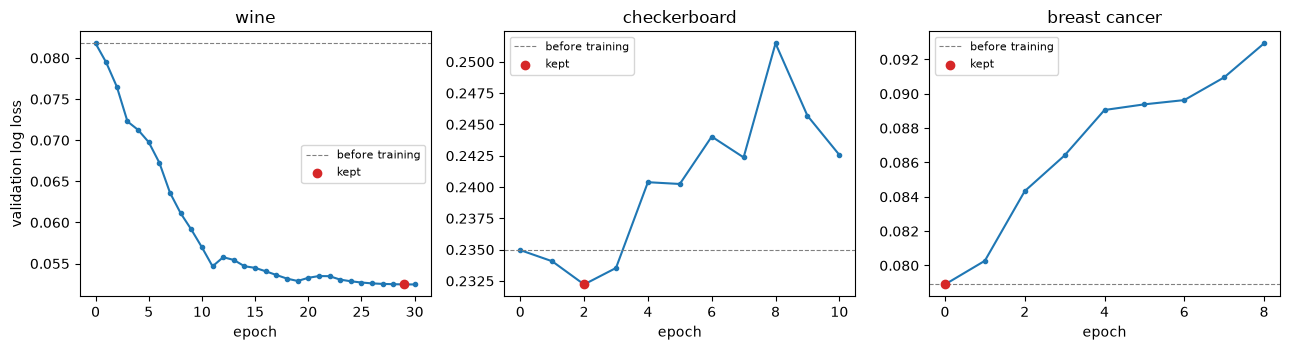

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, info) in zip(axes, curves.items(), strict=True):
    curve = info["val_curve"]  # 0번은 학습 전
    ax.plot(range(len(curve)), curve, marker="o", ms=3)
    ax.axhline(curve[0], color="gray", lw=0.8, ls="--", label="before training")
    best = info["best_epoch"] + 1  # 학습 전이면 0
    ax.scatter([best], [curve[best]], color="tab:red", zorder=3, label="kept")
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("validation log loss")
plt.tight_layout()
plt.show()

점선이 학습 전, 빨간 점이 남긴 epoch입니다. wine은 학습 행이 89개뿐인데도 꾸준히 나아졌습니다. 학습하는 숫자가 4,608개뿐이라 이렇게 작은 데이터에서도 학습해 볼 수 있습니다. 바둑판과 breast cancer처럼 검증 손실이 곧 나빠지는 경우에는 early stopping과 되돌리기가 원래 모델을 지켜 줍니다. 다만 검증 행이 22~75개뿐이라, 검증에서 고른 epoch가 test에서도 나은지는 [03](03_greedy_guard.ipynb)의 out-of-fold처럼 데이터 크기에 달려 있습니다.

## 5. 정리

| | 하는 일 | 저장소 |
|---|---|---|
| 무엇을 학습하나 | attention마다 query 차원별 scale $1 + \delta$ (v2는 4,608개, 모델의 0.06%) | `add_diag_scale` |
| 어떻게 학습하나 | 학습 행 안의 episode(context → query)로, 사전학습과 같은 손실 | `fit_diag_scale` |
| 언제 멈추나 | 검증 행 손실이 가장 좋은 epoch, 8 epoch 동안 나아지지 않으면 멈춤 | `PATIENCE` |
| 해가 되면 | 어떤 epoch도 나아지지 않으면 δ = 0 (원래 모델) | `best_epoch = -1` |

- greedy 선택과 함께 쓸 수 있습니다. `DiagScale(GreedyEnsembleClassifier(...))`처럼 감싸면 δ를 먼저 학습한 모델로 멤버를 고릅니다.
- 학습하는 동안 시간이 들고(여기서는 CPU에서 데이터셋마다 10초 남짓), 예측 시간은 그대로입니다.
- 평가 명령: `scripts/tabpfn_v2/eval.py --test-time diagscale`.